# Step 1. Sample contamination and swapping analysis 

Goal: identify sample swaps and contaminations, via various methods

Work in progress

In [ ]:
from tcr_io.dataset import Dataset
from tcr_io import operations as ops 
from pathlib import Path

In [ ]:
ingested_dir = Path("../data/processed")
dataset_name = "zaslavsky"

ds = Dataset(ingested_dir/dataset_name)
ds

Processed Dataset 'zaslavsky', dataset v8, 
        present loci ['IGH', 'TRB'],
        created_on 2026-10-23, 
        86948924 clonotypes (593 repertoires, 593 patients),
        

In [11]:
ds.run_operation(ops.OverlapAnalyzer())
ds.run_operation(ops.RepertoireHlaInference())

Inferring HLA for repertoires: 100%|██████████| 542/542 [00:09<00:00, 54.86it/s]


[OperationRecord(operation_name='repertoire_hla_inference', version='0.2', description='Infers HLA types from TCR repertoires using the method from HLA2TCR. Does not group by patient', ran_at=datetime.datetime(2026, 10, 23, 15, 20, 19, 307588), duration_s=10.017414093017578, status='success', error=None, params={'model_checkpoint': None}, locus='TRB', outputs=[OutputRecord(name='inferred_hla', template='inferred_hla.parquet', format='PARQUET'), OutputRecord(name='inferred_hla_long', template='inferred_hla_long.parquet', format='PARQUET'), OutputRecord(name='inferred_hla_distance', template='inferred_hla_distance.parquet', format='PARQUET')])]

repertoire_id,repertoire_id_right,hla_dist,hla_dist_binarized
str,str,f64,f64
"""BFI-0000234""","""BFI-0000254""",3.634676,19.0
"""BFI-0000234""","""BFI-0000255""",2.740089,11.0
"""BFI-0000234""","""BFI-0000256""",3.670997,18.0
"""BFI-0000234""","""BFI-0000258""",3.037236,13.0
"""BFI-0000234""","""BFI-0002850""",3.564528,18.0
…,…,…,…
"""BFI-0010800""","""BFI-0010792""",3.288145,14.0
"""BFI-0010806""","""BFI-0010792""",3.796945,19.0
"""BFI-0010800""","""BFI-0010794""",3.371371,17.0


In [ ]:
ds.get_operation_result("repertoire_hla_inference", "inferred_hla_distance")

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def plot_overlap(ds:Dataset, x="hla_dist", y="n_overlap", locus="TRB"):
    ds = ds.select_locus(locus)

    overlap_df = ds.select_locus("TRB").get_result(ops.OverlapAnalyzer.overlap_table).read()
    hla_dist_df = ds.select_locus("TRB").get_result(ops.RepertoireHlaInference.inferred_hla_distance).read()
    overlap_df = overlap_df.join(hla_dist_df, on=["repertoire_id", "repertoire_id_right"], how="left")

    q5, q95 = np.quantile(
        overlap_df["hla_dist"].drop_nulls().to_numpy(),
        [0.05, 0.95]
    )

    fig, axs = plt.subplots(figsize=(8,6), nrows=2, gridspec_kw={"height_ratios":[4,1]}, sharex="col")

    sns.scatterplot(
        data = overlap_df,
        x=x,
        y=y,
        hue="same_patient",
        marker="x",
        size="spearman_corr",
        size_norm=(0,1),
        ax=axs[0]
    )

    sns.kdeplot(
        data = overlap_df,
        x="hla_dist",
        ax=axs[1]
    )

    axs[0].axhline(50, color=(".3", .3), linestyle="--")

    for ax in axs:
        ax.axvline(q5, color=(".3",.3), linestyle="--")
        ax.axvline(q95, color=(".3",.3), linestyle="--")

    return fig, axs, overlap_df

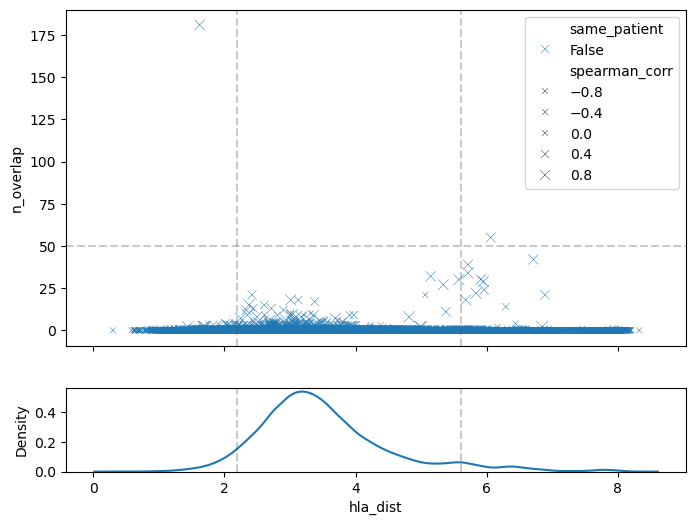

In [25]:
fig, ax, overlap_df = plot_overlap(ds, x="hla_dist", y="n_overlap", locus="TRB")

In [26]:
overlap_df.head(5)

repertoire_id,n_filtered_clonotypes,patient_id,repertoire_id_right,n_filtered_clonotypes_right,patient_id_right,n_overlap,pearson_corr,spearman_corr,same_patient,flag_sus_overlap,flag_sus_overlap_absence,hla_dist,hla_dist_binarized
str,i64,str,str,i64,str,u32,f64,f64,bool,bool,bool,f64,f64
"""BFI-0002859""",984,"""BFI-0002859""","""BFI-0002865""",887,"""BFI-0002865""",181,0.561508,0.754213,false,true,false,1.620511,5.0
"""BFI-0007450""",8549,"""BFI-0007450""","""BFI-0007480""",3331,"""BFI-0007480""",55,0.777623,0.572655,false,true,false,6.064107,59.0
"""BFI-0007453""",13931,"""BFI-0007453""","""BFI-0007483""",2645,"""BFI-0007483""",42,0.962506,0.644923,false,true,false,6.713839,63.0
"""BFI-0007455""",13549,"""BFI-0007455""","""BFI-0007486""",2772,"""BFI-0007486""",39,0.976536,0.632794,false,false,false,5.714365,55.0
"""BFI-0007485""",3778,"""BFI-0007485""","""BFI-0007486""",2772,"""BFI-0007486""",34,0.580921,0.826253,false,false,false,5.71618,49.0
